<a href="https://colab.research.google.com/github/Rahul117590/DeepLearning/blob/main/RecurrentNeuralNetwork.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
from keras import Sequential
from keras.layers import Dense,SimpleRNN


In [2]:
# we add two sequential layer
model=Sequential()
model.add(SimpleRNN(3,input_shape=(4,5)))
model.add(Dense(1,activation='sigmoid'))
model.summary()

/usr/local/lib/python3.13/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ simple_rnn (SimpleRNN)          │ (None, 3)              │            27 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)              │             4 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 31 (124.00 B)

 Trainable params: 31 (124.00 B)

 Non-trainable params: 0 (0.00 B)

In [3]:
# if we wanna know the weight of the rnn
print(model.get_weights()[0].shape)
model.get_weights()[0]

(5, 3)


array([[-0.5560923 ,  0.7227234 , -0.49733013],
       [ 0.11340392, -0.27321017,  0.3362301 ],
       [-0.54751116,  0.59188384, -0.80991125],
       [-0.17304325, -0.39521137, -0.48031667],
       [-0.2781809 ,  0.7957738 ,  0.625714  ]], dtype=float32)

this is the first layer weight of the rnn layer


In [4]:
# 2nd layer
print(model.get_weights()[1].shape)
model.get_weights()[1]

(3, 3)


array([[ 0.47597992, -0.13832733,  0.8685094 ],
       [-0.7701722 , -0.5423419 ,  0.33570835],
       [ 0.42459133, -0.82869226, -0.36467975]], dtype=float32)

In [5]:
# 3rd layer weight
print(model.get_weights()[2].shape)
model.get_weights()[2]

(3,)


array([0., 0., 0.], dtype=float32)

now we build a simple demo project on rnn like how do it work

In [6]:
import numpy as np

In [7]:
docs=['go india',
      'india india',
      'hip hip hurray',
      'jeetega bhai jeetega india jeetega',
      'bharat mata ki jai',
      'kohli kohli',
      'sacine sachine',
      'dhoni dhoni',
      'modi ji ki jai',
      'inquilab zindabad',
      'karo ya maro',
      'nahi kroge to maroge',
      'sabka din aata hai']

In [8]:
# first i need to tokenize the whole thing- like capital latter convert into the small latter , special symbol remove into the sentense
from tensorflow.keras.preprocessing.text import Tokenizer
tokenizer=Tokenizer(oov_token='<nothing>')# oov=out of vocabaliary

In [9]:
# convert our docs text into the tocken
tokenizer.fit_on_texts(docs)

In [10]:
# how many unique word in the out text
tokenizer.word_index

{'<nothing>': 1,
 'india': 2,
 'jeetega': 3,
 'hip': 4,
 'ki': 5,
 'jai': 6,
 'kohli': 7,
 'dhoni': 8,
 'go': 9,
 'hurray': 10,
 'bhai': 11,
 'bharat': 12,
 'mata': 13,
 'sacine': 14,
 'sachine': 15,
 'modi': 16,
 'ji': 17,
 'inquilab': 18,
 'zindabad': 19,
 'karo': 20,
 'ya': 21,
 'maro': 22,
 'nahi': 23,
 'kroge': 24,
 'to': 25,
 'maroge': 26,
 'sabka': 27,
 'din': 28,
 'aata': 29,
 'hai': 30}

In [11]:
# count the word which wrod how many times
tokenizer.word_counts

OrderedDict([('go', 1),
             ('india', 4),
             ('hip', 2),
             ('hurray', 1),
             ('jeetega', 3),
             ('bhai', 1),
             ('bharat', 1),
             ('mata', 1),
             ('ki', 2),
             ('jai', 2),
             ('kohli', 2),
             ('sacine', 1),
             ('sachine', 1),
             ('dhoni', 2),
             ('modi', 1),
             ('ji', 1),
             ('inquilab', 1),
             ('zindabad', 1),
             ('karo', 1),
             ('ya', 1),
             ('maro', 1),
             ('nahi', 1),
             ('kroge', 1),
             ('to', 1),
             ('maroge', 1),
             ('sabka', 1),
             ('din', 1),
             ('aata', 1),
             ('hai', 1)])

In [12]:
#  now convert the documents into the time series
sequences=tokenizer.texts_to_sequences(docs)
sequences

[[9, 2],
 [2, 2],
 [4, 4, 10],
 [3, 11, 3, 2, 3],
 [12, 13, 5, 6],
 [7, 7],
 [14, 15],
 [8, 8],
 [16, 17, 5, 6],
 [18, 19],
 [20, 21, 22],
 [23, 24, 25, 26],
 [27, 28, 29, 30]]

In [13]:
# now apply padding
from tensorflow.keras.preprocessing.sequence import pad_sequences
sequences=pad_sequences(sequences,padding='post')


In [14]:
sequences

array([[ 9,  2,  0,  0,  0],
       [ 2,  2,  0,  0,  0],
       [ 4,  4, 10,  0,  0],
       [ 3, 11,  3,  2,  3],
       [12, 13,  5,  6,  0],
       [ 7,  7,  0,  0,  0],
       [14, 15,  0,  0,  0],
       [ 8,  8,  0,  0,  0],
       [16, 17,  5,  6,  0],
       [18, 19,  0,  0,  0],
       [20, 21, 22,  0,  0],
       [23, 24, 25, 26,  0],
       [27, 28, 29, 30,  0]], dtype=int32)

In [15]:
# now we analaysis a data set tht is prebuild on the keras library
from keras.datasets import imdb
from keras import Sequential
from keras.layers import Dense,SimpleRNN,Embedding,Flatten

In [16]:
(X_train,y_train),(X_test,y_test)=imdb.load_data()

17464789/17464789 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


In [17]:
X_train

array([list([1, 14, 22, 16, 43, 530, 973, 1622, 1385, 65, 458, 4468, 66, 3941, 4, 173, 36, 256, 5, 25, 100, 43, 838, 112, 50, 670, 22665, 9, 35, 480, 284, 5, 150, 4, 172, 112, 167, 21631, 336, 385, 39, 4, 172, 4536, 1111, 17, 546, 38, 13, 447, 4, 192, 50, 16, 6, 147, 2025, 19, 14, 22, 4, 1920, 4613, 469, 4, 22, 71, 87, 12, 16, 43, 530, 38, 76, 15, 13, 1247, 4, 22, 17, 515, 17, 12, 16, 626, 18, 19193, 5, 62, 386, 12, 8, 316, 8, 106, 5, 4, 2223, 5244, 16, 480, 66, 3785, 33, 4, 130, 12, 16, 38, 619, 5, 25, 124, 51, 36, 135, 48, 25, 1415, 33, 6, 22, 12, 215, 28, 77, 52, 5, 14, 407, 16, 82, 10311, 8, 4, 107, 117, 5952, 15, 256, 4, 31050, 7, 3766, 5, 723, 36, 71, 43, 530, 476, 26, 400, 317, 46, 7, 4, 12118, 1029, 13, 104, 88, 4, 381, 15, 297, 98, 32, 2071, 56, 26, 141, 6, 194, 7486, 18, 4, 226, 22, 21, 134, 476, 26, 480, 5, 144, 30, 5535, 18, 51, 36, 28, 224, 92, 25, 104, 4, 226, 65, 16, 38, 1334, 88, 12, 16, 283, 5, 16, 4472, 113, 103, 32, 15, 16, 5345, 19, 178, 32]),
       list([1, 194, 1

data is already interger encoded so that why it show the number

In [18]:
X_train.shape

(25000,)

In [19]:
X_train[0]

[1,
 14,
 22,
 16,
 43,
 530,
 973,
 1622,
 1385,
 65,
 458,
 4468,
 66,
 3941,
 4,
 173,
 36,
 256,
 5,
 25,
 100,
 43,
 838,
 112,
 50,
 670,
 22665,
 9,
 35,
 480,
 284,
 5,
 150,
 4,
 172,
 112,
 167,
 21631,
 336,
 385,
 39,
 4,
 172,
 4536,
 1111,
 17,
 546,
 38,
 13,
 447,
 4,
 192,
 50,
 16,
 6,
 147,
 2025,
 19,
 14,
 22,
 4,
 1920,
 4613,
 469,
 4,
 22,
 71,
 87,
 12,
 16,
 43,
 530,
 38,
 76,
 15,
 13,
 1247,
 4,
 22,
 17,
 515,
 17,
 12,
 16,
 626,
 18,
 19193,
 5,
 62,
 386,
 12,
 8,
 316,
 8,
 106,
 5,
 4,
 2223,
 5244,
 16,
 480,
 66,
 3785,
 33,
 4,
 130,
 12,
 16,
 38,
 619,
 5,
 25,
 124,
 51,
 36,
 135,
 48,
 25,
 1415,
 33,
 6,
 22,
 12,
 215,
 28,
 77,
 52,
 5,
 14,
 407,
 16,
 82,
 10311,
 8,
 4,
 107,
 117,
 5952,
 15,
 256,
 4,
 31050,
 7,
 3766,
 5,
 723,
 36,
 71,
 43,
 530,
 476,
 26,
 400,
 317,
 46,
 7,
 4,
 12118,
 1029,
 13,
 104,
 88,
 4,
 381,
 15,
 297,
 98,
 32,
 2071,
 56,
 26,
 141,
 6,
 194,
 7486,
 18,
 4,
 226,
 22,
 21,
 134,
 476,
 26,
 480,
 5

In [20]:
# now we made all the lenght of word be same -- like padding
X_train=pad_sequences(X_train,padding='post',maxlen=50)
X_test=pad_sequences(X_test,padding='post',maxlen=50)

we just take out the first 50 word of the sentences

In [21]:
X_train.shape

(25000, 50)

In [23]:
# view the first 50 words
X_train[0]

array([2071,   56,   26,  141,    6,  194, 7486,   18,    4,  226,   22,
         21,  134,  476,   26,  480,    5,  144,   30, 5535,   18,   51,
         36,   28,  224,   92,   25,  104,    4,  226,   65,   16,   38,
       1334,   88,   12,   16,  283,    5,   16, 4472,  113,  103,   32,
         15,   16, 5345,   19,  178,   32], dtype=int32)

In [24]:
# now make the rnn model for this data
model=Sequential()
model.add(SimpleRNN(32,input_shape=(50,1),return_sequences=False))#return_sequence=false means give output in the end
model.add(Dense(1,activation='sigmoid'))
model.summary()

/usr/local/lib/python3.13/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ simple_rnn_1 (SimpleRNN)        │ (None, 32)             │         1,088 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,121 (4.38 KB)

 Trainable params: 1,121 (4.38 KB)

 Non-trainable params: 0 (0.00 B)

In [27]:
# now we complie the model
model.compile(loss='binary_crossentropy',optimizer='adam',metrics=['accuracy'])
# fit the model in the data
history=model.fit(X_train,y_train,epochs=5,validation_data=(X_test,y_test))

Epoch 1/5
782/782 ━━━━━━━━━━━━━━━━━━━━ 10s 11ms/step - accuracy: 0.5089 - loss: 0.6922 - val_accuracy: 0.5037 - val_loss: 0.6963
Epoch 2/5
782/782 ━━━━━━━━━━━━━━━━━━━━ 6s 8ms/step - accuracy: 0.5083 - loss: 0.6924 - val_accuracy: 0.5026 - val_loss: 0.6950
Epoch 3/5
782/782 ━━━━━━━━━━━━━━━━━━━━ 8s 10ms/step - accuracy: 0.5062 - loss: 0.6922 - val_accuracy: 0.5064 - val_loss: 0.6936
Epoch 4/5
782/782 ━━━━━━━━━━━━━━━━━━━━ 6s 8ms/step - accuracy: 0.5123 - loss: 0.6923 - val_accuracy: 0.5039 - val_loss: 0.6942
Epoch 5/5
782/782 ━━━━━━━━━━━━━━━━━━━━ 6s 8ms/step - accuracy: 0.5096 - loss: 0.6922 - val_accuracy: 0.5010 - val_loss: 0.6950


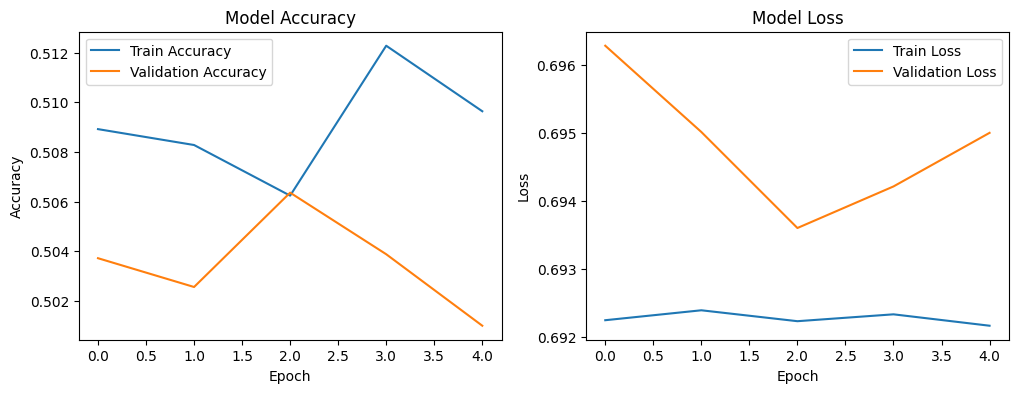

In [28]:
# now we plot the graph of the models accuracy and validation
import matplotlib.pyplot as plt

# Accuracy graph
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], label='Train Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.title('Model Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()

# Loss graph
plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], label='Train Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title('Model Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()

plt.show()

this model do not give the much better result because i dont use the whole data we only use the first 50 sentense of the data so that why...
now we use the embadding technique rather than padding with same data set

**Embedding**

In [41]:
# we do the same process
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.utils import pad_sequences
from keras.datasets import imdb
from keras import Sequential
from keras.layers import Dense,Embedding,SimpleRNN,Embedding,Flatten,Input

In [42]:
(X_train,y_train),(X_test,y_test)=imdb.load_data()

In [43]:
# now apply the padding for first 50 words
X_train=pad_sequences(X_train,padding='post',maxlen=50)# only take the first 50 data that help to easily train our models
X_test=pad_sequences(X_test,padding='post',maxlen=50)

In [44]:
X_train.shape

(25000, 50)

In [45]:
# now applying the model and embadding technique

model=Sequential()
model.add(Input(shape=(50,)))
model.add(Embedding(10000,2))
model.add(SimpleRNN(32,return_sequences=False))
model.add(Dense(1,activation='sigmoid'))
model.summary()

Model: "sequential_8"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_4 (Embedding)         │ (None, 50, 2)          │        20,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ simple_rnn_4 (SimpleRNN)        │ (None, 32)             │         1,120 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 21,153 (82.63 KB)

 Trainable params: 21,153 (82.63 KB)

 Non-trainable params: 0 (0.00 B)

In [46]:
#now compile the model
model.compile(loss='binary_crossentropy',metrics=['accuracy'],optimizer='adam')
history=model.fit(X_train,y_train,epochs=5,validation_data=(X_test,y_test))

Epoch 1/5
782/782 ━━━━━━━━━━━━━━━━━━━━ 12s 12ms/step - accuracy: 0.5817 - loss: 0.6521 - val_accuracy: 0.7623 - val_loss: 0.5034
Epoch 2/5
782/782 ━━━━━━━━━━━━━━━━━━━━ 7s 8ms/step - accuracy: 0.8066 - loss: 0.4273 - val_accuracy: 0.8031 - val_loss: 0.4313
Epoch 3/5
782/782 ━━━━━━━━━━━━━━━━━━━━ 11s 9ms/step - accuracy: 0.8494 - loss: 0.3518 - val_accuracy: 0.7884 - val_loss: 0.4573
Epoch 4/5
782/782 ━━━━━━━━━━━━━━━━━━━━ 6s 8ms/step - accuracy: 0.8700 - loss: 0.3171 - val_accuracy: 0.7919 - val_loss: 0.4692
Epoch 5/5
782/782 ━━━━━━━━━━━━━━━━━━━━ 7s 9ms/step - accuracy: 0.8789 - loss: 0.3013 - val_accuracy: 0.7877 - val_loss: 0.5104


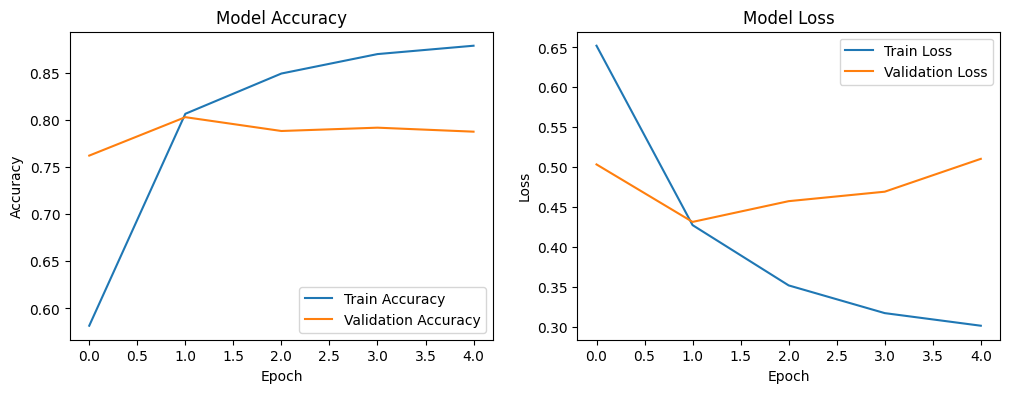

In [47]:
import matplotlib.pyplot as plt

# Accuracy graph
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], label='Train Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.title('Model Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()

# Loss graph
plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], label='Train Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title('Model Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()

plt.show()

we simpily see the result of befor embadding and after embedding